<div align="center">

# Universidad Autónoma del Estado de México
## Centro Universitario UAEM Zumpango
### Ingeniería en Computación


**Asignatura:** Investigación de Operaciones

**Actividad integradora** 

**Prácticas:** 

- Árbol de expansión mínima
- Ruta crítica
- Algoritmo de Dijkstra

**Integrantes:**
- Perez Sixto Sophia Guadalupe
- Parra Benavides Jerson Jarhid

**Fecha:** 19 de noviembre de 2026

</div>

## Bibliotecas que se usan en todo el cuaderno

Se usan Python 3, NetworkX (grafos), Matplotlib (gráficas), NumPy, Pandas (tablas). Cada práctica vuelve a importar lo que necesita para que se pueda ejecutar por separado.

# Práctica 1. Algoritmo de expansión mínima (Prim).

## Título del problema
Red de cableado para 8 áreas de un edificio de TI.

## Descripción y planteamiento
Una empresa de tecnología tiene 8 áreas (1 a 8) y necesita conectarlas con cable de red. No todas las áreas se pueden unir directamente y cada tramo posible tiene un costo (en cientos de pesos, que depende de la distancia y de la obra). Se busca conectar todas las áreas gastando lo menos posible**, sin hacer ciclos que sobren.

Esto es justo un árbol de expansión mínima: un conjunto de aristas que une todos los nodos, sin ciclos, con la suma de pesos más chica.

## Algoritmo de Prim (pasos de la clase)
- **Paso 0:** $C_0 = \emptyset$ y $\bar{C}_0 = N$.
- **Paso 1:** se elige un nodo cualquiera para iniciar. Ese nodo pasa a $C_1$ y los demás quedan en $\bar{C}_1$.
- **Paso k:** de todas las aristas que unen un nodo de $C$ con uno de $\bar{C}$, se escoge la de menor peso. El nodo nuevo pasa de $\bar{C}$ a $C$.
- Se repite hasta que $\bar{C}$ quede vacío.

Paso 1: Importar las bibliotecas que vamos a necesitar.

In [73]:
!pip install networkx matplotlib

Defaulting to user installation because normal site-packages is not writeable


In [74]:
import networkx as nx  # Esta libreria sirve para armar y manejar grafos.
import matplotlib.pyplot as plt  # Esta esta para hacer las graficas.

Paso 2: Definir los datos: la lista de cables posibles con su costo y las posiciones de los nodos (solo sirven para que el dibujo se vea ordenado).

In [75]:
aristas = [  # Lista de cables posibles, cada uno es (nodo A, nodo B, costo).
    (1, 2, 4),  # Cable entre 1 y 2 cuesta 4.
    (1, 3, 3),  # Cable entre 1 y 3 cuesta 3.
    (2, 3, 2),  # Cable entre 2 y 3 cuesta 2.
    (2, 4, 5),  # Cable entre 2 y 4 cuesta 5.
    (3, 4, 7),  # Cable entre 3 y 4 cuesta 7.
    (3, 5, 6),  # Cable entre 3 y 5 cuesta 6.
    (4, 5, 1),  # Cable entre 4 y 5 cuesta 1.
    (4, 6, 8),  # Cable entre 4 y 6 cuesta 8.
    (5, 6, 3),  # Cable entre 5 y 6 cuesta 3.
    (5, 7, 9),  # Cable entre 5 y 7 cuesta 9.
    (6, 7, 2),  # Cable entre 6 y 7 cuesta 2.
    (6, 8, 6),  # Cable entre 6 y 8 cuesta 6.
    (7, 8, 4),  # Cable entre 7 y 8 cuesta 4.
    (2, 5, 10), # Cable entre 2 y 5 cuesta 10.
]



posiciones = {  # Donde va a quedar cada nodo en el dibujo.
    1: (0, 2), 2: (2, 3), 3: (2, 1), 4: (4, 3),  # Nodos 1 al 4.
    5: (4, 1), 6: (6, 3), 7: (6, 1), 8: (8, 2),  # Nodos 5 al 8.
}

G = nx.Graph()  # Crear un grafo vacio.
for a, b, peso in aristas:  # Recorrer cada cable de la lista.
    G.add_edge(a, b, weight=peso)  # Lo meto al grafo con su costo.


print("Nodos:", list(G.nodes()))  # Muestro los nodos.
print("Numero de aristas:", G.number_of_edges())  # Muestro cuantas aristas hay.

Nodos: [1, 2, 3, 4, 5, 6, 7, 8]
Numero de aristas: 14


Paso 2.1: Matriz de adyacencia: Otra forma de representar la red es una matriz: el renglón es el nodo de salida, la columna es el nodo de llegada y cada celda guarda el costo del cable (0 significa que no hay cable directo). Como la red no tiene dirección, la matriz queda simétrica.

In [76]:
import pandas as pd  # Para mostrar la matriz como tabla.
nodos = [1, 2, 3, 4, 5, 6, 7, 8]  # Lista de nodos para los renglones y columnas.
matriz = pd.DataFrame(0, index=nodos, columns=nodos)  # Matriz llena de ceros al inicio.
for a, b, peso in aristas:  # Recorre cada cable.
    matriz.loc[a, b] = peso  # Se pone el costo en la posicion (A, B).
    matriz.loc[b, a] = peso  # Y tambien en la (B, A) porque va en los dos sentidos.
print(matriz)  # Muestro la matriz de adyacencia.

   1   2  3  4   5  6  7  8
1  0   4  3  0   0  0  0  0
2  4   0  2  5  10  0  0  0
3  3   2  0  7   6  0  0  0
4  0   5  7  0   1  8  0  0
5  0  10  6  1   0  3  9  0
6  0   0  0  8   3  0  2  6
7  0   0  0  0   9  2  0  4
8  0   0  0  0   0  6  4  0


Paso 3: Dibujamos la red original con los costos sobre cada arista.

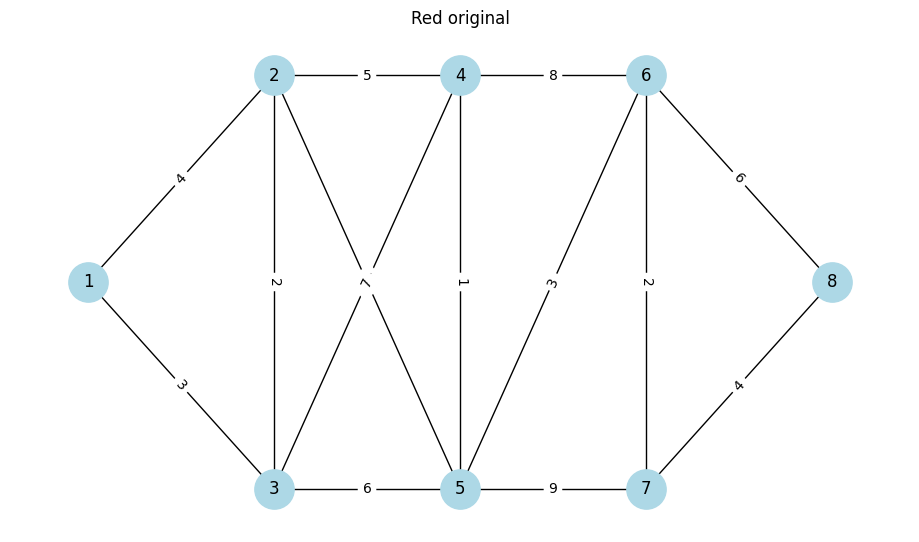

In [77]:
plt.figure(figsize=(9, 5))  # Tamaño de la figura
nx.draw(G, posiciones, with_labels=True, node_color="lightblue", node_size= 800, font_size=12)  # Dibujar nodos y lineas.
pesos = nx.get_edge_attributes(G, "weight")  # Saco los pesos de las aristas.
nx.draw_networkx_edge_labels(G, posiciones, edge_labels =pesos)  # Escribe los pesos en el dibujo.
plt.title("Red original")  # Titulo.
plt.show()  # Mostrar la grafica.

Paso 4: Aplicar Prim paso a paso. En cada paso se imprimen los conjuntos $C$ y $\bar{C}$, el arco elegido y su longitud, igual que en el ejemplo de clase (Midwest TV Cable). Además, en cada paso se dibuja el **mini árbol** que se lleva hasta ese momento, con la distancia de cada arco y la suma acumulada $L_A$.

Paso 1 : C = [1]  C barra = [2, 3, 4, 5, 6, 7, 8]


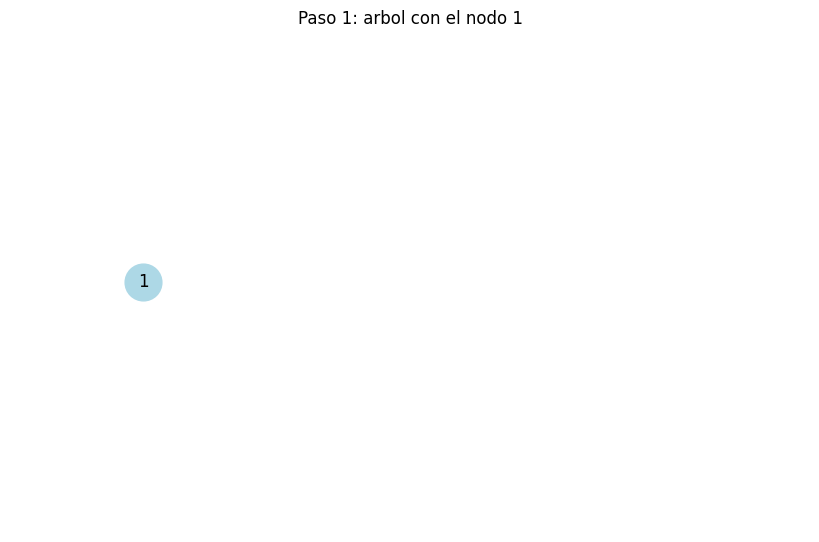

Paso 2 : C = [1, 3]  C prima = [2, 4, 5, 6, 7, 8]
Arco ( 1 , 3 )  Longitud = 3
L_A2 = 3 = 3


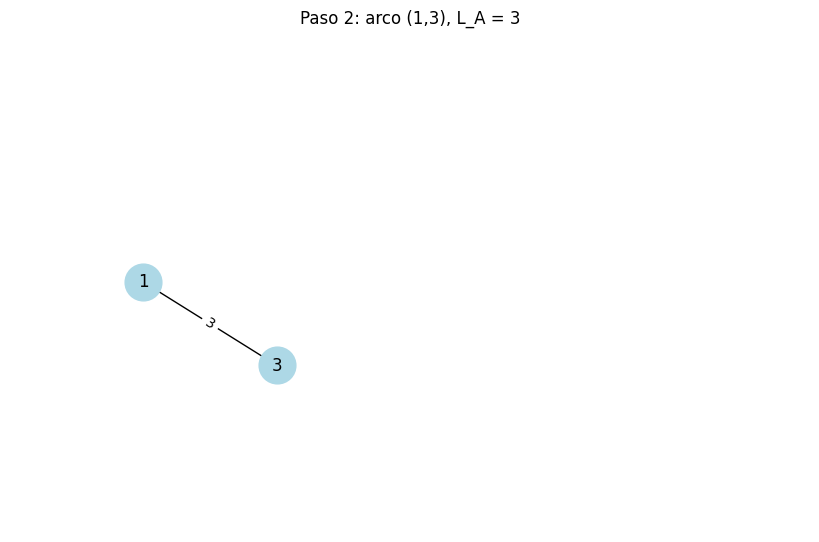

Paso 3 : C = [1, 3, 2]  C prima = [4, 5, 6, 7, 8]
Arco ( 2 , 3 )  Longitud = 2
L_A3 = 3 + 2 = 5


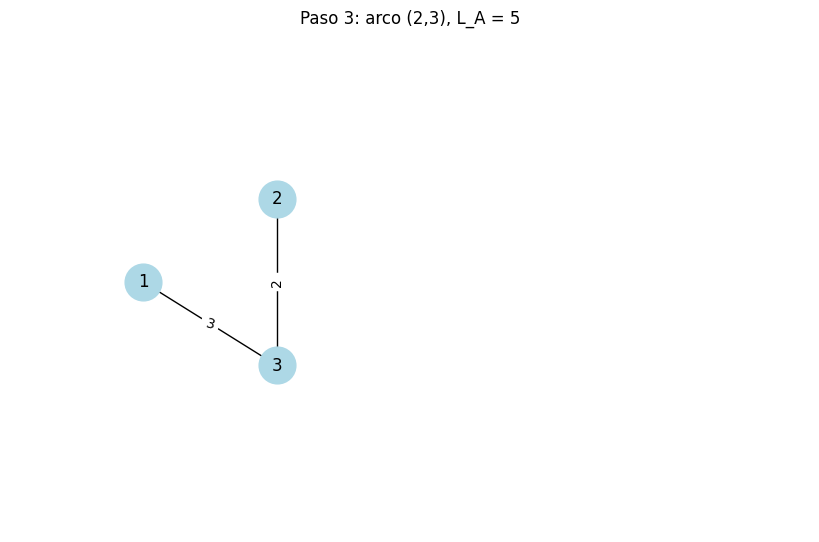

Paso 4 : C = [1, 3, 2, 4]  C prima = [5, 6, 7, 8]
Arco ( 2 , 4 )  Longitud = 5
L_A4 = 3 + 2 + 5 = 10


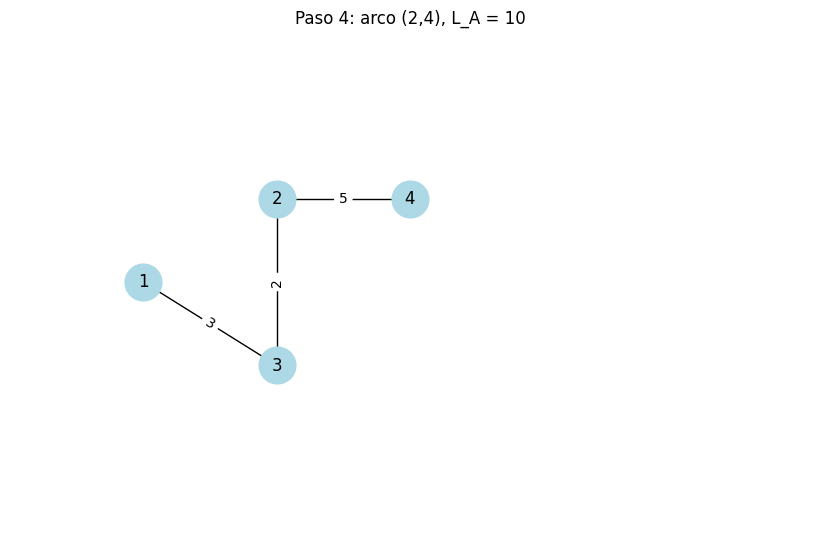

Paso 5 : C = [1, 3, 2, 4, 5]  C prima = [6, 7, 8]
Arco ( 4 , 5 )  Longitud = 1
L_A5 = 3 + 2 + 5 + 1 = 11


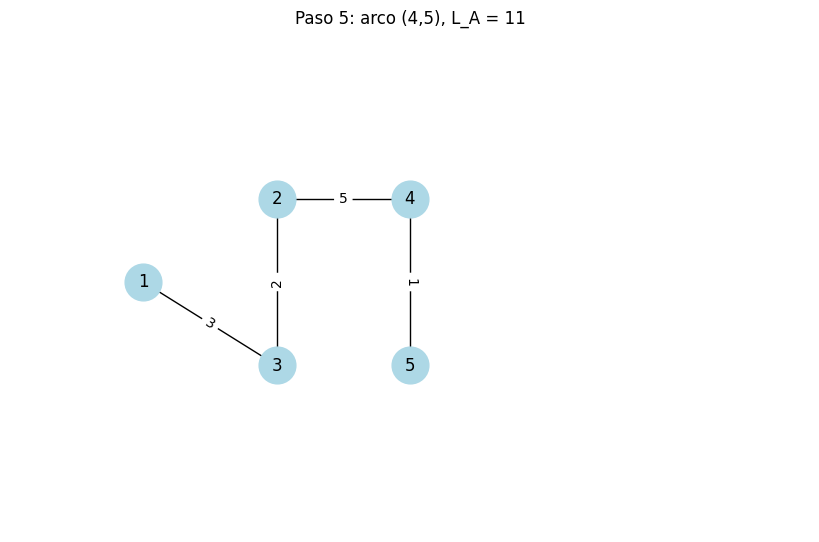

Paso 6 : C = [1, 3, 2, 4, 5, 6]  C prima = [7, 8]
Arco ( 5 , 6 )  Longitud = 3
L_A6 = 3 + 2 + 5 + 1 + 3 = 14


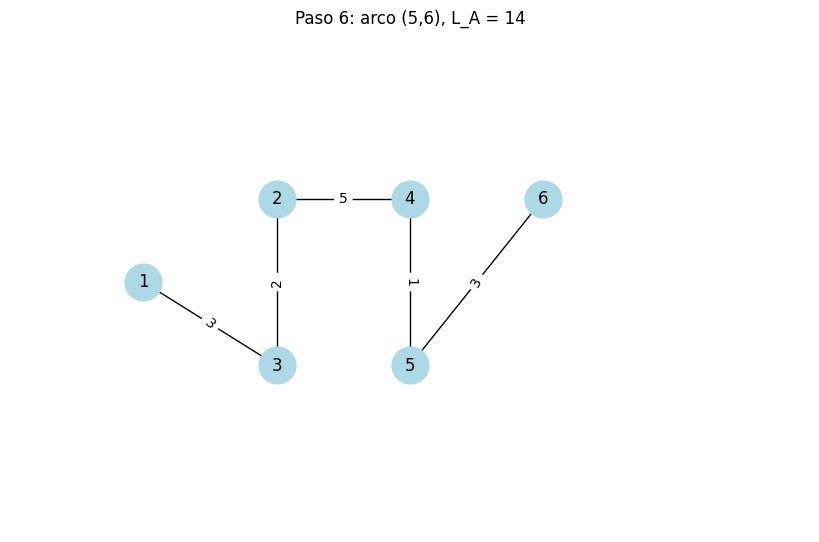

Paso 7 : C = [1, 3, 2, 4, 5, 6, 7]  C prima = [8]
Arco ( 6 , 7 )  Longitud = 2
L_A7 = 3 + 2 + 5 + 1 + 3 + 2 = 16


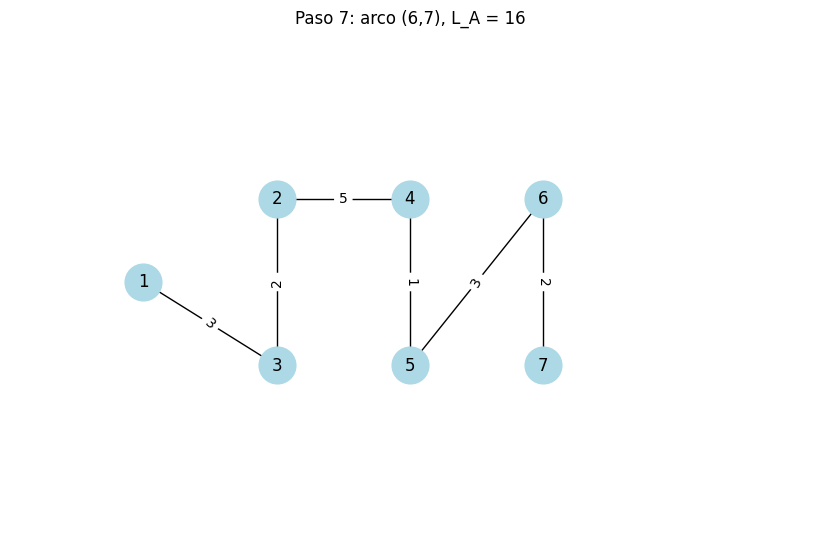

Paso 8 : C = [1, 3, 2, 4, 5, 6, 7, 8]  C prima = []
Arco ( 7 , 8 )  Longitud = 4
L_A8 = 3 + 2 + 5 + 1 + 3 + 2 + 4 = 20


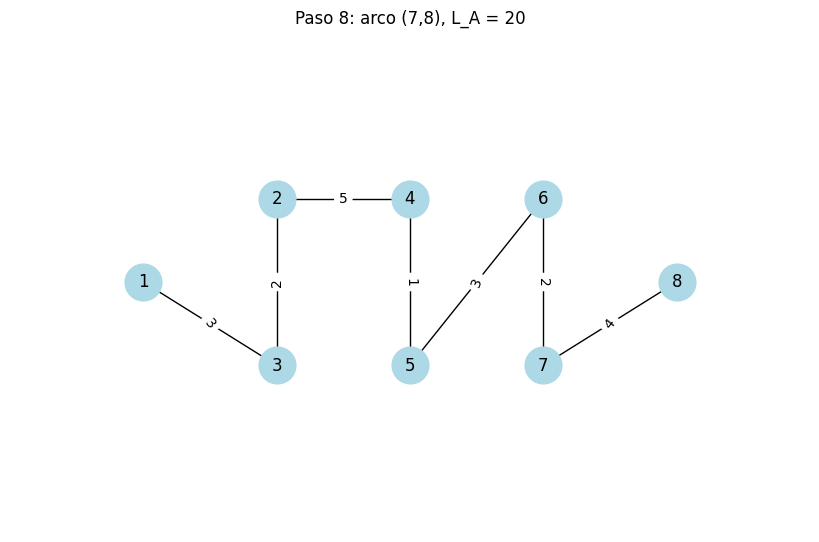


Aristas del arbol: [(1, 3, 3), (2, 3, 2), (2, 4, 5), (4, 5, 1), (5, 6, 3), (6, 7, 2), (7, 8, 4)]
Costo minimo total: 20


In [78]:

C = [1]  # Empiezo en el nodo 1 (podria ser cualquiera sin problema).
C_barra = [2, 3, 4, 5, 6, 7, 8]  # Los demas nodos todavia no estan conectados.
arbol = []  # Aqui va guardando las aristas que se eligen.
longitudes = []  # Aqui se va la longitud de cada arco elegido.
costo_total = 0  # Aca va sumando el costo.
paso = 1  # Contador de pasos.


mini = nx.Graph()  # Este es el mini arbol que voy armando paso a paso.
mini.add_node(1)  # El arbol empieza solo con el nodo 1.


def dibujar_mini(titulo):  # Funcion chiquita para dibujar el mini arbol de cada paso.
    plt.figure(figsize=(8, 5))  # Tamaño de la figura
    nx.draw(mini, posiciones, with_labels=True, node_color="lightblue", node_size=700)  # Dibujo nodos y lineas
    pesos_mini = nx.get_edge_attributes(mini, "weight")  # Sacar los pesos del mini arbol.
    nx.draw_networkx_edge_labels(mini, posiciones, edge_labels=pesos_mini)  # Los escribe en el dibujo.
    plt.xlim(-2, 10)  # Mismo limite en X para que todos los dibujos queden igual.
    plt.ylim(-1, 5)  # Mismo limite en Y.
    plt.title(titulo)  
    plt.show()  

print("Paso", paso, ": C =", C, " C barra =", C_barra)  # Muestro el paso 1.
dibujar_mini("Paso 1: arbol con el nodo 1")  # Dibujo el arbol del paso 1.


while len(C_barra) > 0:  # Mientras falten nodos por conectar...
    mejor = None  # Todavia no tengo ninguna arista elegida.
    for a, b, peso in aristas:  # Revisa todas las aristas.
        une = (a in C and b in C_barra) or (b in C and a in C_barra)  # Checo si une un nodo de C con uno de C barra.
        if une:  # Si cumple
            if mejor is None or peso < mejor[2]:  # Y es mas barata que la mejor que llevo.
                mejor = (a, b, peso)  # La guardo como la mejor.
    a, b, peso = mejor  # Separo los datos de la arista elegida.
    if a in C:  # Si el nodo A ya estaba en C.
        nuevo = b  # Entonces el nuevo es B.
    else:  # Si no.
        nuevo = a  # El nuevo es A.
    C.append(nuevo)  # El nodo nuevo pasa a C.
    C_barra.remove(nuevo)  # Y se quita de C barra.
    arbol.append(mejor)  # Guarda la arista en el arbol.
    longitudes.append(peso)  # Guardo su longitud
    costo_total = costo_total + peso  # Suma su costo
    mini.add_edge(a, b, weight=peso)  # Agrego la arista al mini arbol.
    paso = paso + 1  # Avanza el paso.
    suma = " + ".join(str(l) for l in longitudes)  # Armar el texto de la suma. 
    print("Paso", paso, ": C =", C, " C prima =", C_barra)  # Muestro conjuntos.
    print("Arco (", a, ",", b, ")  Longitud =", peso)  # Muestro el arco y su longitud.
    print("L_A" + str(paso), "=", suma, "=", costo_total)  # Muestro la suma acumulada
    dibujar_mini("Paso " + str(paso) + ": arco (" + str(a) + "," + str(b) + "), L_A = " + str(costo_total))  # Dibuja el mini arbol de este paso.

print("\nAristas del arbol:", arbol)  # Lista final de aristas.
print("Costo minimo total:", costo_total)  # Costo final.


Paso 5: Dibuja la solución: las aristas del árbol de expansión mínima en rojo y las demás en gris.

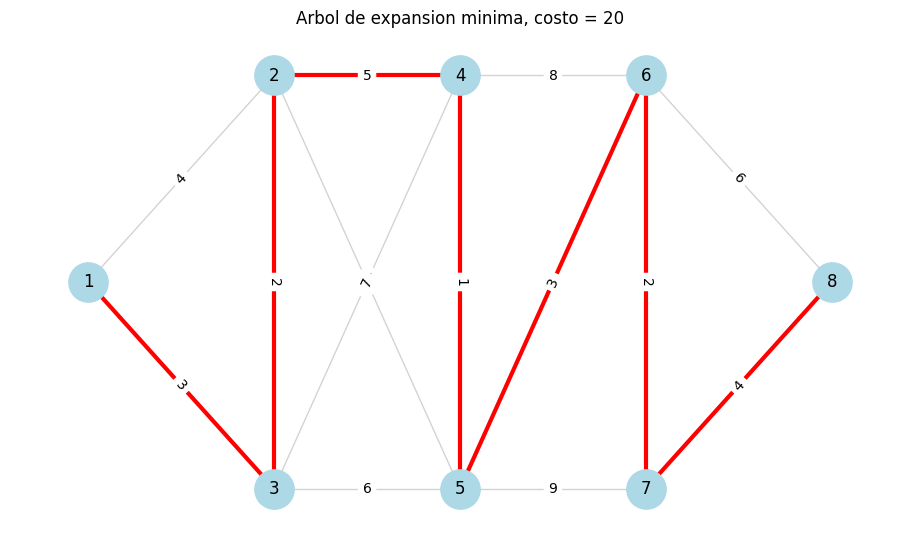

In [79]:
plt.figure(figsize=(9, 5))  # Tamaño de la figura.
nx.draw(G, posiciones, with_labels=True, node_color="lightblue", node_size=800, edge_color="lightgray")  # BibujA la red en gris.
aristas_arbol = [(a, b) for a, b, peso in arbol]  # Saca solo los nodos de cada arista elegida.
nx.draw_networkx_edges(G, posiciones, edgelist=aristas_arbol, edge_color="red", width=3)  # Las pinta de rojo y mas gruesas.
nx.draw_networkx_edge_labels(G, posiciones, edge_labels=pesos)  # Pongo los pesos
plt.title("Arbol de expansion minima, costo = " + str(costo_total))  # Titulo con el costo
plt.show() 

Paso 6: Comprobamos el resultado con la función de NetworkX para ver que coincida.

In [80]:
T = nx.minimum_spanning_tree(G, algorithm="prim")  # NetworkX calcula su propio arbol minimo.
print("Costo con NetworkX:", T.size(weight="weight"))  # Costo del arbol de NetworkX.
print("Costo con mi codigo:", costo_total)  # Costo de mi codigo.

Costo con NetworkX: 20.0
Costo con mi codigo: 20


**Paso 6.1.** Matriz de adyacencia del árbol de expansión mínima: solo quedan los cables elegidos por Prim. La suma de todos los valores dividida entre 2 debe dar el costo total.

In [81]:
matriz_arbol = pd.DataFrame(0, index=nodos, columns=nodos)  # Matriz de ceros para el arbol.
for a, b, peso in arbol:  # Recorrer solo las aristas elegidas.
    matriz_arbol.loc[a, b] = peso  # Pone el costo en (A, B).
    matriz_arbol.loc[b, a] = peso  # Y en (B, A).
print(matriz_arbol)  # Muestra la matriz del arbol.
print("\nSuma de la matriz entre 2:", matriz_arbol.values.sum() / 2)  # Debe dar 20, igual que el costo total.

   1  2  3  4  5  6  7  8
1  0  0  3  0  0  0  0  0
2  0  0  2  5  0  0  0  0
3  3  2  0  0  0  0  0  0
4  0  5  0  0  1  0  0  0
5  0  0  0  1  0  3  0  0
6  0  0  0  0  3  0  2  0
7  0  0  0  0  0  2  0  4
8  0  0  0  0  0  0  4  0

Suma de la matriz entre 2: 20.0


1.5 Interpretación de resultados

El algoritmo de Prim eligió 7 aristas (una menos que el número de nodos, como debe ser en un árbol): (1,3), (2,3), (2,4), (4,5), (5,6), (6,7) y (7,8), con costos 3, 2, 5, 1, 3, 2 y 4.

Costo mínimo total = 20 (cientos de pesos). El resultado coincide con el de `nx.minimum_spanning_tree`, así que el código está bien.

Se quedaron fuera los cables caros como (5,7) con 9, (2,5) con 10, (4,6) con 8 y (3,4) con 7. Usarlos solo subiría el costo o formaría ciclos que no hacen falta, porque ya hay otra forma más barata de llegar a esos nodos. Con esta red, todas las áreas quedan comunicadas gastando lo mínimo posible.

### Aplicación al área de TI
Este mismo problema aparece cuando se diseña el cableado de una red LAN o se conectan sucursales con enlaces de fibra: el árbol de expansión mínima da la forma más barata de que todos los equipos queden comunicados.

# Práctica 2: Ruta crítica (PERT/CPM)

## Título del problema
Planeación de un proyecto de 10 actividades.

## Descripción y planteamiento
Se tiene un proyecto con 10 actividades (A a J). Cada una tiene una duración en días y algunas necesitan que otras terminen antes (precedencias). Queremos saber **cuánto dura el proyecto completo** y **qué actividades no se pueden retrasar** sin atrasar todo.

| Actividad | Precedencia | Duración (días) |
|---|---|---|
| A | – | 4 |
| B | – | 6 |
| C | – | 5 |
| D | A, B | 7 |
| E | B, C | 5 |
| F | B, C | 4 |
| G | C | 5 |
| H | D, E, F, G | 6 |
| I | F, G | 8 |
| J | H, I | 3 |

## Formulación matemática
Para cada actividad, si llamamos duración al tiempo que tarda en hacerse, estos conceptos se entienden así de simple:

**Inicio temprano:** Es lo más pronto que puede empezar una actividad. Se toma el fin temprano más alto de las actividades que van justo antes (si no tiene ninguna antes, empieza en 0).

**Fin temprano:** Es lo más pronto que puede terminar una actividad. Solo sumas su inicio temprano más su duración.

**Fin tardío:** Es lo más tarde que puede terminar una actividad sin retrasar todo el proyecto. Se toma el inicio tardío más pequeño de las actividades que van justo después (si no tiene ninguna después, equivale a la duración total del proyecto).

**Inicio tardío:** Es lo más tarde que puede empezar una actividad sin retrasar el final. Tomas su fin tardío y le restas su duración.

**Holgura:** Es el margen o tiempo extra que tiene una actividad antes de empezar a atrasar el proyecto. Se calcula restando su inicio tardío menos su inicio temprano.

La ruta crítica son las actividades con holgura cero. La duración del proyecto es el mayor fin temprano.

Paso 1: Importaar las bibliotecas.

In [82]:
import pandas as pd  # Para hacer la tabla de resultados.
import networkx as nx  # Para dibujar la red del proyecto.
import matplotlib.pyplot as plt  #Ppara las graficas.

Paso 2: Capturamos los datos del proyecto (duración y predecesoras de cada actividad).

In [83]:
duracion = {  # cuantos dias dura cada actividad
    "A": 4, "B": 6, "C": 5, "D": 7, "E": 5,  # Actividades A a E.
    "F": 4, "G": 5, "H": 6, "I": 8, "J": 3,  # Actividades F a J.
}

predecesoras = {  # Que actividades deben terminar antes de cada una.
    "A": [], "B": [], "C": [],  # Estas no dependen de nadie.
    "D": ["A", "B"],  # D necesita A y B.
    "E": ["B", "C"],  # E necesita B y C.
    "F": ["B", "C"],  # F necesita B y C.
    "G": ["C"],  # G necesita C.
    "H": ["D", "E", "F", "G"],  # H necesita D, E, F y G.
    "I": ["F", "G"],  # I necesita F y G.
    "J": ["H", "I"],  # J necesita H e I.
}



actividades = list(duracion.keys())  # Lista de actividades en orden (ya estan ordenadas por precedencia).
print(actividades)  # La muestro para revisar.

['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']


Paso 3: Pasada hacia adelante. Calculamos inicio temprano (IT) y fin temprano (FT). Se recorren las actividades de la A a la J.

In [84]:
IT = {}  # Aca guardo el inicio temprano.
FT = {}  # Aca guardo el fin temprano.

for act in actividades:  # Recorro las actividades en orden.
    if len(predecesoras[act]) == 0:  # Si no tiene predecesoras.
        IT[act] = 0  # Empieza en el dia 0.
    else:  # Si si tiene predecesoras.
        IT[act] = max(FT[p] for p in predecesoras[act])  # Empieza cuando termina la ultima de ellas.
    FT[act] = IT[act] + duracion[act]  # El fin es el inicio mas la duracion.
    print(act, ": IT =", IT[act], " FT =", FT[act])  # Iimprime cada resultado.


duracion_total = max(FT.values())  # El proyecto dura lo que dure la actividad que termina al ultimo.
print("\nDuracion total del proyecto:", duracion_total, "dias") 

A : IT = 0  FT = 4
B : IT = 0  FT = 6
C : IT = 0  FT = 5
D : IT = 6  FT = 13
E : IT = 6  FT = 11
F : IT = 6  FT = 10
G : IT = 5  FT = 10
H : IT = 13  FT = 19
I : IT = 10  FT = 18
J : IT = 19  FT = 22

Duracion total del proyecto: 22 dias


Paso 4. Pasada hacia atrás. Calculamos fin tardío (FL) e inicio tardío (IL). Ahora se recorren las actividades de la J a la A.

In [85]:
sucesoras = {act: [] for act in actividades}  # Diccionario vacio para saber quien depende de quien.
for act in actividades:  # Recorrs todas las actividades.
    for p in predecesoras[act]:  # Recorro sus predecesoras.
        sucesoras[p].append(act)  # A cada predecesora le anoto que act viene despues.

IL = {}  # Aca guardo el inicio tardio.
FL = {}  # Aca guardo el fin tardio.

for act in reversed(actividades):  # Recorr de atras para adelante.
    if len(sucesoras[act]) == 0:  # Si nadie depende de ella.
        FL[act] = duracion_total  # Puede terminar hasta el final del proyecto.
    else:  # Si alguien depende de ella.
        FL[act] = min(IL[s] for s in sucesoras[act])  # Termina cuando debe empezar la primera que sigue.
    IL[act] = FL[act] - duracion[act]  # El inicio tardio es el fin tardio menos la duracion.
    print(act, ": IL =", IL[act], " FL =", FL[act])

J : IL = 19  FL = 22
I : IL = 11  FL = 19
H : IL = 13  FL = 19
G : IL = 6  FL = 11
F : IL = 7  FL = 11
E : IL = 8  FL = 13
D : IL = 6  FL = 13
C : IL = 1  FL = 6
B : IL = 0  FL = 6
A : IL = 2  FL = 6


Paso 5: Calcular las holguras y armar la tabla completa.

In [86]:
holgura = {}  # Aca guardo las holguras.
for act in actividades:  # Recorre las actividades.
    holgura[act] = IL[act] - IT[act]  # holgura = inicio tardio - inicio temprano.

tabla = pd.DataFrame({  # Armq la tabla con todo.
    "Duracion": duracion,  # Columna de duraciones.
    "IT": IT,  # Inicio temprano.
    "FT": FT,  # Fin temprano.
    "IL": IL,  # Inicio tardio.
    "FL": FL,  # Fin tardio.
    "Holgura": holgura,  # Holgura.
})
tabla["Critica"] = tabla["Holgura"] == 0  # Marca True si la holgura es cero.
print(tabla) 

   Duracion  IT  FT  IL  FL  Holgura  Critica
A         4   0   4   2   6        2    False
B         6   0   6   0   6        0     True
C         5   0   5   1   6        1    False
D         7   6  13   6  13        0     True
E         5   6  11   8  13        2    False
F         4   6  10   7  11        1    False
G         5   5  10   6  11        1    False
H         6  13  19  13  19        0     True
I         8  10  18  11  19        1    False
J         3  19  22  19  22        0     True


Paso 6: Identifición la ruta crítica.

In [87]:
ruta_critica = [act for act in actividades if holgura[act] == 0]  # Actividades con holgura cero.
print("Actividades criticas:", ruta_critica)  # Enseño esas.
print("Ruta critica:", " - ".join(ruta_critica))  # Las muestro en forma de ruta,
print("Suma de duraciones criticas:", sum(duracion[a] for a in ruta_critica))  # Debe dar igual a la duracion total.

Actividades criticas: ['B', 'D', 'H', 'J']
Ruta critica: B - D - H - J
Suma de duraciones criticas: 22


Paso 7: Dibuja la red del proyecto. Las actividades y flechas críticas van en rojo.

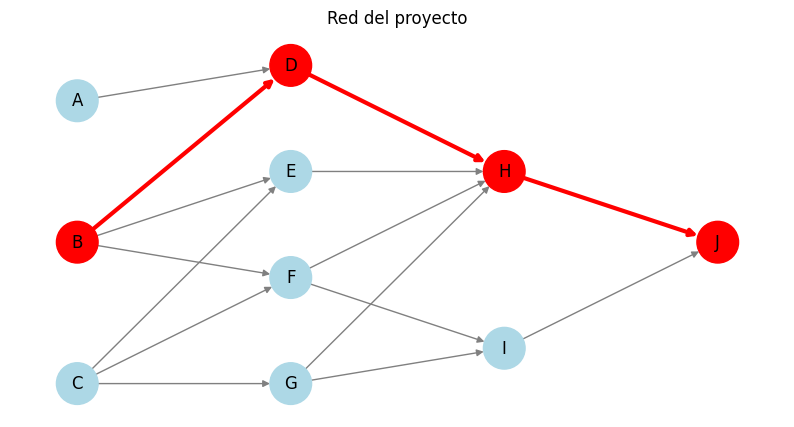

In [88]:
G2 = nx.DiGraph()  # Grafo dirigido porque hay un orden.
for act in actividades:  # Recorre las actividades.
    for p in predecesoras[act]:  # Recorre sus predecesoras.
        G2.add_edge(p, act)  # Dibujo una flecha de la predecesora a la actividad.

pos2 = {  # Posiciones para que se vea ordenado.
    "A": (0, 4), "B": (0, 2), "C": (0, 0),  # Primera columna.
    "D": (1, 4.5), "E": (1, 3), "F": (1, 1.5), "G": (1, 0),  # Segunda columna.
    "H": (2, 3), "I": (2, 0.5),  # Tercera columna.
    "J": (3, 2),  # Cuarta columna.
}

colores = ["red" if holgura[n] == 0 else "lightblue" for n in G2.nodes()]  # Rojo si es critica.
flechas_criticas = [(u, v) for u, v in G2.edges() if holgura[u] == 0 and holgura[v] == 0 and FT[u] == IT[v]]  # Flechas entre criticas.
otras = [e for e in G2.edges() if e not in flechas_criticas]  # Las demas flechas.

plt.figure(figsize=(10, 5)) 
nx.draw_networkx_nodes(G2, pos2, node_color=colores, node_size=900)  # Dibuja los nodos
nx.draw_networkx_labels(G2, pos2)  # Ponner las letras.
nx.draw_networkx_edges(G2, pos2, edgelist=otras, edge_color="gray", node_size=900)  # Flechas normales.
nx.draw_networkx_edges(G2, pos2, edgelist=flechas_criticas, edge_color="red", width=3, node_size=900)  # Flechas criticas.
plt.title("Red del proyecto") 
plt.axis("off")  # Quito los ejes.
plt.show()  

### Interpretación de resultados

El proyecto dura 22 días. La ruta crítica es B - D - H - J (6 + 7 + 6 + 3 = 22 días) y tiene holgura 0, o sea que cualquier retraso en una de esas actividades atrasa todo el proyecto.

Las demás actividades tienen holgura: A (2 días), E (2 días), C, F, G e I (1 día cada una). Esas se pueden mover un poco sin afectar la fecha final. 

### Aplicación al área de TI
La ruta crítica se usa para planear proyectos de software y de infraestructura (por ejemplo, un despliegue de sistema con diseño, desarrollo, pruebas y capacitación) y saber en qué tareas no se puede perder tiempo.

# Práctica 3. Algoritmo de Dijkstra

## Título del problema
Ruta más corta entre dos routers de una red de 8 nodos.

## Descripción y planteamiento
Se tiene una red con 8 routers (1 a 8). Cada enlace tiene un costo (puede verse como latencia en milisegundos). Se quiere saber cuál es el camino con menor costo total del nodo 1 al nodo 8.

## Formulación matemática
Sea $d(j)$ la distancia acumulada del nodo origen al nodo $j$:

$$d(1) = 0, \qquad d(j) = \min_i \{ d(i) + w_{ij} \}$$

Cada nodo lleva una etiqueta $[a, b]$, donde $a$ es la distancia acumulada y $b$ el nodo predecesor. Las etiquetas pueden ser **temporales** o **permanentes**.

## Algoritmo de Dijkstra (pasos de la clase)
1. Se etiqueta el primer nodo con etiqueta permanente.
2. Desde ese nodo se asigna a sus vecinos una etiqueta temporal con su distancia y nodo predecesor.
3. Entre todas las etiquetas temporales se elige la de menor distancia y se hace permanente (los empates se resuelven al azar).
4. Se repite hasta que todos los nodos tengan etiqueta permanente.
5. La información de cada nodo queda en sus etiquetas permanentes.

Paso 1: Importamos las bibliotecas.

In [89]:
import networkx as nx  
import matplotlib.pyplot as plt  

Paso 2: Defino la red; enlaces con su costo y posiciones para dibujar.

In [90]:
enlaces = [  # Lista de enlaces: (nodo A, nodo B, costo).
    (1, 2, 7),  # 1 con 2 cuesta 7.
    (1, 3, 9),  # 1 con 3 cuesta 9.
    (1, 6, 14),  # 1 con 6 cuesta 14.
    (2, 3, 10),  # 2 con 3 cuesta 10.
    (2, 4, 15),  # 2 con 4 cuesta 15.
    (3, 4, 11),  # 3 con 4 cuesta 11.
    (3, 6, 2),  # 3 con 6 cuesta 2.
    (4, 5, 6),  # 4 con 5 cuesta 6.
    (5, 6, 9),  # 5 con 6 cuesta 9.
    (5, 7, 5),  # 5 con 7 cuesta 5.
    (6, 7, 12),  # 6 con 7 cuesta 12.
    (6, 8, 16),  # 6 con 8 cuesta 16.
    (7, 8, 3),  # 7 con 8 cuesta 3.
]

posiciones = {  # Posiciones de los nodos en el dibujo.
    1: (0, 2), 2: (2, 4), 3: (2, 2), 4: (4, 4),  # Nodos 1 al 4.
    5: (6, 4), 6: (4, 1), 7: (6, 1), 8: (8, 2.5),  # Nodos 5 al 8.
}

G3 = nx.Graph()  # Grafo vacio.
for a, b, costo in enlaces:  # Recorrr los enlaces.
    G3.add_edge(a, b, weight=costo)  # Los agrego con su costo.

origen = 1  # Nodo de salida.

destino = 8  # Nodo de llegada.
print("Nodos:", list(G3.nodes()))  

Nodos: [1, 2, 3, 6, 4, 5, 7, 8]


Paso 2.1: Matriz de adyacencia. Igual que en la práctica 1: renglón = nodo de salida, columna = nodo de llegada, y cada celda guarda el costo del enlace (0 = no hay enlace directo).

In [91]:
import pandas as pd  # Para mostrar la matriz como tabla.

nodos = [1, 2, 3, 4, 5, 6, 7, 8]  # Lista de nodos para los renglones y columnas.
matriz = pd.DataFrame(0, index=nodos, columns=nodos)  # Matriz llena de ceros al inicio.
for a, b, costo in enlaces:  #Rrecorro cada enlace.
    matriz.loc[a, b] = costo  # Pongo el costo en (A, B).
    matriz.loc[b, a] = costo  # Y en (B, A) porque va en los dos sentidos.
print(matriz) 

    1   2   3   4  5   6   7   8
1   0   7   9   0  0  14   0   0
2   7   0  10  15  0   0   0   0
3   9  10   0  11  0   2   0   0
4   0  15  11   0  6   0   0   0
5   0   0   0   6  0   9   5   0
6  14   0   2   0  9   0  12  16
7   0   0   0   0  5  12   0   3
8   0   0   0   0  0  16   3   0


Paso 3: Dibujar la red original.

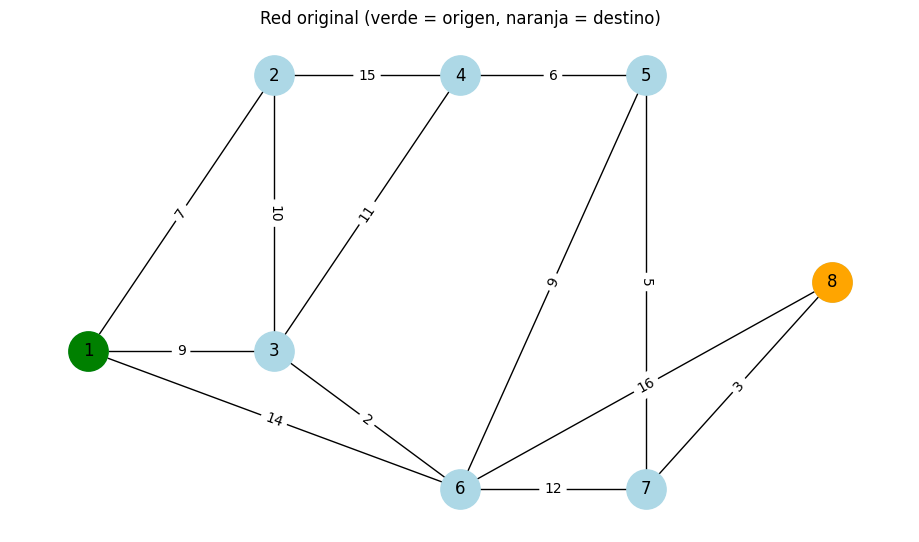

In [92]:
plt.figure(figsize=(9, 5))  # Tamaño.
nx.draw(G3, posiciones, with_labels=True, node_color="lightblue", node_size= 800)  # Nodos y lineas
nx.draw_networkx_nodes(G3, posiciones, nodelist=[origen], node_color="green", node_size=800)  # Origen en verde.
nx.draw_networkx_nodes(G3, posiciones, nodelist=[destino], node_color="orange", node_size=800)  # Destino en naranja.
costos = nx.get_edge_attributes(G3, "weight")  # Sco los costos.
nx.draw_networkx_edge_labels(G3, posiciones, edge_labels=costos)  # Los escribe en el dibujo.
plt.title("Red original (verde = origen, naranja = destino)")  
plt.show()  # muestro

Paso 4: Programamos Dijkstra. Primero armamos las listas de vecinos y las etiquetas; luego, en cada iteración, se vuelve permanente la etiqueta temporal más pequeña y se actualizan los vecinos.

In [93]:
vecinos = {n: [] for n in G3.nodes()}  # Cada nodo con su lista de vecinos.
for a, b, costo in enlaces:  # Recorre los enlaces.
    vecinos[a].append((b, costo))  # B es vecino de A.
    vecinos[b].append((a, costo))  # A es vecino de B (la red va en los dos sentidos).

infinito = 999999  #Uun numero enorme que hace de infinito.
distancia = {n: infinito for n in G3.nodes()}  # Al inicio todos estan bien lejisimos.
predecesor = {n: None for n in G3.nodes()}  # Todavia nadie tiene predecesor.
permanentes = []  # Nodos con etiqueta permanente.


distancia[origen] = 0  # El origen esta a distancia 0.
iteracion = 1  # Contador de iteraciones.



while len(permanentes) < len(G3.nodes()):  # Mientras falten nodos por hacer permanentes.
    actual = None  # Todavia no elige nodo.
    for n in G3.nodes():  # Revisa todos los nodos.
        if n not in permanentes:  # Solo los que no son permanentes.
            if actual is None or distancia[n] < distancia[actual]:  # }El de menor distancia temporal.
                actual = n  
    permanentes.append(actual)  # Su etiqueta pasa a ser permanente.
    print("Iteracion", iteracion, "- etiqueta permanente del nodo", actual, ": [", distancia[actual], ",", predecesor[actual], "]")  # Print.
    for vecino, costo in vecinos[actual]:  # Revisa los vecinos del nodo actual.
        if vecino not in permanentes:  # Si todavia no es permanente...
            nueva = distancia[actual] + costo  # Distancia pasando por el nodo actual.
            if nueva < distancia[vecino]:  # Si es mejor que la que tenia...
                distancia[vecino] = nueva  # Actualizo la distancia.
                predecesor[vecino] = actual  # Y su predecesor
                print("      etiqueta temporal del nodo", vecino, ": [", nueva, ",", actual, "]")  
    iteracion = iteracion + 1  # Sigo con la siguiente iteracion.

Iteracion 1 - etiqueta permanente del nodo 1 : [ 0 , None ]
      etiqueta temporal del nodo 2 : [ 7 , 1 ]
      etiqueta temporal del nodo 3 : [ 9 , 1 ]
      etiqueta temporal del nodo 6 : [ 14 , 1 ]
Iteracion 2 - etiqueta permanente del nodo 2 : [ 7 , 1 ]
      etiqueta temporal del nodo 4 : [ 22 , 2 ]
Iteracion 3 - etiqueta permanente del nodo 3 : [ 9 , 1 ]
      etiqueta temporal del nodo 4 : [ 20 , 3 ]
      etiqueta temporal del nodo 6 : [ 11 , 3 ]
Iteracion 4 - etiqueta permanente del nodo 6 : [ 11 , 3 ]
      etiqueta temporal del nodo 5 : [ 20 , 6 ]
      etiqueta temporal del nodo 7 : [ 23 , 6 ]
      etiqueta temporal del nodo 8 : [ 27 , 6 ]
Iteracion 5 - etiqueta permanente del nodo 4 : [ 20 , 3 ]
Iteracion 6 - etiqueta permanente del nodo 5 : [ 20 , 6 ]
Iteracion 7 - etiqueta permanente del nodo 7 : [ 23 , 6 ]
      etiqueta temporal del nodo 8 : [ 26 , 7 ]
Iteracion 8 - etiqueta permanente del nodo 8 : [ 26 , 7 ]


Paso 5: Reconstruir la ruta del origen al destino siguiendo los predecesores desde el final hacia atrás.

In [94]:
ruta = []  # Lista donde armo la ruta.
nodo = destino  # Empieza desde el destino.
while nodo is not None:  # Mientras haya predecesor...
    ruta.append(nodo)  # Agrega el nodo.
    nodo = predecesor[nodo]  # Me voy al predecesor.
ruta.reverse()  # La volteo para que quede de origen a destino.

print("Ruta mas corta:", " - ".join(str(n) for n in ruta))  # Enseña. 
print("Distancia total:", distancia[destino])  # Muestro la distancia total.
print("\nEtiquetas finales [distancia, predecesor]")  
for n in sorted(G3.nodes()):  # Recorrw los nodos en orden.
    print("Nodo", n, ": [", distancia[n], ",", predecesor[n], "]") 

Ruta mas corta: 1 - 3 - 6 - 7 - 8
Distancia total: 26

Etiquetas finales [distancia, predecesor]
Nodo 1 : [ 0 , None ]
Nodo 2 : [ 7 , 1 ]
Nodo 3 : [ 9 , 1 ]
Nodo 4 : [ 20 , 3 ]
Nodo 5 : [ 20 , 6 ]
Nodo 6 : [ 11 , 3 ]
Nodo 7 : [ 23 , 6 ]
Nodo 8 : [ 26 , 7 ]


Paso 6: Dibuja la ruta más corta en rojo.

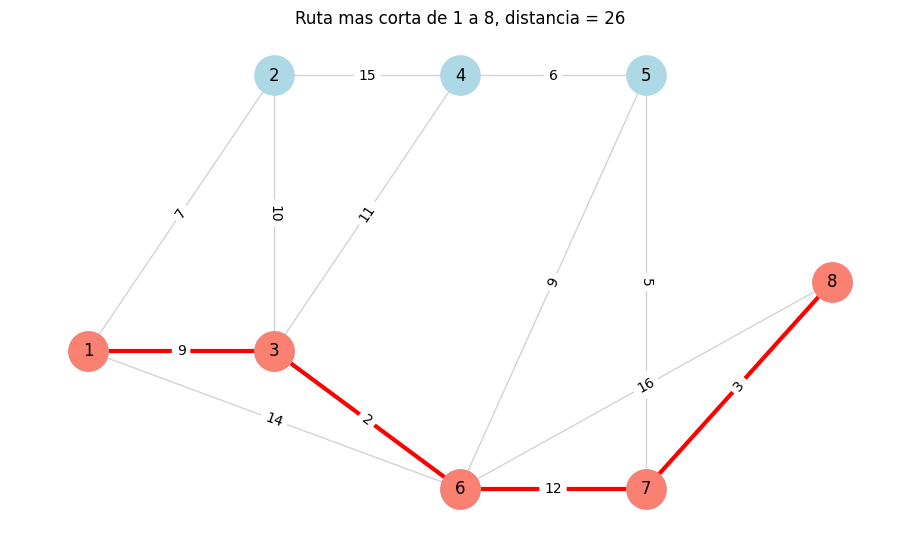

In [95]:
aristas_ruta = [(ruta[i], ruta[i + 1]) for i in range(len(ruta) - 1)]  # Pares de nodos consecutivos de la ruta.
plt.figure(figsize=(9, 5)) 
nx.draw(G3, posiciones, with_labels=True, node_color="lightblue", node_size=800, edge_color="lightgray")  # Red en gris.
nx.draw_networkx_nodes(G3, posiciones, nodelist=ruta, node_color="salmon", node_size=800)  # Nodos de la ruta.
nx.draw_networkx_edges(G3, posiciones, edgelist=aristas_ruta, edge_color="red", width=3)  # Aristas de la ruta.
nx.draw_networkx_edge_labels(G3, posiciones, edge_labels=costos)  # Costos
plt.title("Ruta mas corta de " + str(origen) + " a " + str(destino) + ", distancia = " + str(distancia[destino]))  # Titulo.
plt.show()  

**Paso 7.** Comprobamos con la función de NetworkX.

In [96]:
ruta_nx = nx.dijkstra_path(G3, origen, destino)  # Ruta calculada por NetworkX.
dist_nx = nx.dijkstra_path_length(G3, origen, destino)  # Distancia calculada por NetworkX.
print("NetworkX:", ruta_nx, "distancia", dist_nx)  # Enhseña lo de NetworkX.
print("Mi codigo:", ruta, "distancia", distancia[destino])  # Enseño lo de mi codigo.

NetworkX: [1, 3, 6, 7, 8] distancia 26
Mi codigo: [1, 3, 6, 7, 8] distancia 26


### Interpretación de resultados

La ruta más corta del nodo 1 al nodo 8 es 1 - 3 - 6 - 7 - 8 con una distancia total de 26. El resultado coincide con `nx.dijkstra_path`.

Se ve en las etiquetas que la ruta directa 1 - 6 (costo 14) no conviene, porque pasando por el nodo 3 se llega al 6 con solo 11 (9 + 2). Esa etiqueta temporal del nodo 6 se corrigió de [14, 1] a [11, 3] en la iteración 3. Del mismo modo, llegar a 8 desde 6 cuesta 27, pero pasando por el 7 baja a 26.

Dijkstra funciona porque todos los costos son positivos: una vez que una etiqueta es permanente, ya no se puede mejorar.

### Aplicación al área de TI
Los protocolos de enrutamiento como OSPF usan Dijkstra para que cada router calcule el camino de menor costo hacia los demás equipos de la red.

# Conclusiones

## Conclusiones individuales
**Pérez Sixto Sophia Guadalupe:** Es un tema interesante, conocer y saber la mejor ruta es importante para optimizar un problema, trabajarlo con herramientas de programación es mucho mas exacto incluso y con mejores resultados.  

**Parra Benavides Jerson Jarhid:** Solia pensar que la materia no era muy relevante, pero saber encontrar la ruta más conveniente es clave para optimizar cualquier problema, y usar programación hace que todo sea mucho más exacto. Aplicar los grafos me dejó ver con claridad cómo se conectan los nodos y cómo se forman las rutas. Al final, escribir el código paso a paso ayudó a entender mejor cómo funcionan los algoritmos por dentro.



## Conclusión del equipo
En esta actividad aplicamos tres modelos clave de Investigación de Operaciones usando Python y los comprobamos de forma muy sencilla con NetworkX. Los resultados obtenidos fueron muy claros: con Prim alcanzamos una red optimizada con un costo mínimo de 20; con CPM identificamos que el proyecto tomará 22 días a través de la ruta crítica B-D-H-J; y con Dijkstra encontramos el camino más eficiente entre los nodos 1 y 8, logrando un costo de 26.
Construir los algoritmos paso a paso, en lugar de depender únicamente de una función automática, marcó toda la diferencia. Nos permitió ver con calma cómo funciona cada proceso por dentro y entender el sentido de cada cifra. Gracias a este ejercicio, ahora resulta mucho más fácil visualizar cómo se aplican estos conceptos en el día a día de las tecnologías de la información, ya sea para organizar redes o para estructurar la planeación de un proyecto con claridad.